# Advanced EEG Experiments

This notebook investigates potential improvements in cross-subject motor imagery classification based on findings from recent research.

Previous exploratory evaluation achieved a balanced accuracy of 0.539 using three-channel CSP + LDA.

This result motivated further experiments with channel selection, temporal windows, and alternative EEG feature representations.

## Research Objectives

We investigate:

- Motor-related EEG channel selection (3, 6, and 15 channels).
- Temporal window selection and baseline normalization.
- Filter Bank CSP (FBCSP).
- Additional spatial and frequency-domain representations.

## Evaluation Strategy

Subjects S001–S020 are used for model development and subject-aware cross-validation.

Previously unseen subjects will be reserved for a new independent evaluation after model selection.

Balanced accuracy is the primary metric, with Macro-F1 as a secondary metric.

## 1. Motor Channel Selection

The previous CSP experiments evaluated 3 and 64 EEG channels. We now investigate whether intermediate motor-cortex channel configurations provide better cross-subject performance.
## Channel Configuration Rationale

The evaluated channel sets were selected based on prior motor imagery EEG literature.

- **3 channels (C3, Cz, C4)** were used as a minimal motor-cortex baseline.
- **5 channels (C3, C1, Cz, C2, C4)** were included to test whether adding medial central electrodes improves CSP performance.
- **6 channels (C3, Cz, C4, CP3, CPz, CP4)** and  
  **15 channels (FC3, FC1, FCz, FC2, FC4, C3, C1, Cz, C2, C4, CP3, CP1, CPz, CP2, CP4)**  
  were based on the low-channel motor imagery study by Tuimebay et al. (2026), which systematically compared sensorimotor channel configurations on the PhysioNet EEG Motor Movement/Imagery dataset.

The goal of this experiment is not to assume that larger channel sets are better, but to evaluate whether adding sensorimotor electrodes improves cross-subject CSP + LDA performance under identical preprocessing and validation conditions.

In [1]:
from pathlib import Path
import mne

data_dir = Path("../data/raw")
raw = mne.io.read_raw_edf(data_dir / "S001R04.edf", preload=False, verbose=False)

motor_channels_15 = ["FC3", "FC1", "FCz", "FC2", "FC4",
                     "C3", "C1", "Cz", "C2", "C4",
                     "CP3", "CP1", "CPz", "CP2", "CP4"]

available_channels = {ch.rstrip(".").upper(): ch for ch in raw.ch_names}

channel_check = {channel: available_channels.get(channel.upper())
                 for channel in motor_channels_15}

print("Available motor channels:")
for channel, original_name in channel_check.items():
    print(f"{channel}: {original_name}")

missing_channels = [channel for channel, original_name in channel_check.items()
                    if original_name is None]

print("\nMissing channels:", missing_channels)
assert not missing_channels, "Some motor channels are unavailable."

Available motor channels:
FC3: Fc3.
FC1: Fc1.
FCz: Fcz.
FC2: Fc2.
FC4: Fc4.
C3: C3..
C1: C1..
Cz: Cz..
C2: C2..
C4: C4..
CP3: Cp3.
CP1: Cp1.
CPz: Cpz.
CP2: Cp2.
CP4: Cp4.

Missing channels: []


### EEG Preparation for Motor Channel Configurations

We prepare EEG epochs using four predefined sensorimotor channel configurations (3, 5, 6, and 15 channels).

All configurations share identical preprocessing, epoch timing, and class labels. This allows us to isolate the effect of channel selection on CSP performance.

In [2]:
import numpy as np

subjects = [f"S{i:03d}" for i in range(1, 21)]
runs = ["04", "08", "12"]

# Motor channel configurations
channels_3 = ["C3", "Cz", "C4"]
channels_5 = ["C3", "C1", "Cz", "C2", "C4"]
channels_6 = ["C3", "Cz", "C4", "CP3", "CPz", "CP4"]
channels_15 = motor_channels_15

X_list = []
y_list = []
groups_list = []

for subject in subjects:
    for run in runs:
        recording_id = f"{subject}R{run}"
        raw_path = data_dir / f"{recording_id}.edf"

        raw = mne.io.read_raw_edf(raw_path, preload=True, verbose=False)
        raw.set_eeg_reference(ref_channels="average", projection=False, verbose=False)
        raw.filter(l_freq=8.0, h_freq=30.0, picks="eeg", verbose=False)

        events, event_id = mne.events_from_annotations(raw, verbose=False)

        channel_lookup = {ch.rstrip(".").upper(): ch for ch in raw.ch_names}
        selected_channels = [channel_lookup[ch.upper()] for ch in channels_15]

        epochs = mne.Epochs(raw, events, event_id={"T1": event_id["T1"], "T2": event_id["T2"]}, tmin=0.0, tmax=4.0, 
                            picks="eeg", baseline=None, preload=True, reject_by_annotation=True, verbose=False)

        epochs.pick(selected_channels)
        epochs.reorder_channels(selected_channels)

        X_list.append(epochs.get_data())
        y_list.append(np.where(epochs.events[:, -1] == event_id["T1"], 0, 1))
        groups_list.extend([subject] * len(epochs))

X_15 = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list)
groups = np.array(groups_list)

def select_channels(X, selected, available):
    indices = [available.index(ch) for ch in selected]
    return X[:, indices, :]

X_3 = select_channels(X_15, channels_3, channels_15)
X_5 = select_channels(X_15, channels_5, channels_15)
X_6 = select_channels(X_15, channels_6, channels_15)

print("3 channels:", X_3.shape)
print("5 channels:", X_5.shape)
print("6 channels:", X_6.shape)
print("15 channels:", X_15.shape)
print("Class distribution:", np.bincount(y))
print("Subjects:", len(np.unique(groups)))

3 channels: (900, 3, 641)
5 channels: (900, 5, 641)
6 channels: (900, 6, 641)
15 channels: (900, 15, 641)
Class distribution: [455 445]
Subjects: 20


### Visualization of Evaluated Channel Configurations

The following figure shows the motor-related electrode configurations used in the CSP channel selection experiment.

The compared sets include 3-, 5-, 6-, and 15-channel sensorimotor configurations motivated by previous motor imagery EEG studies.

/var/folders/g4/6_7xrsfn2f1g437zc2mv6fzh0000gn/T/ipykernel_48960/1041756903.py:12: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw_vis.set_montage("standard_1005", match_case=False, on_missing="ignore")


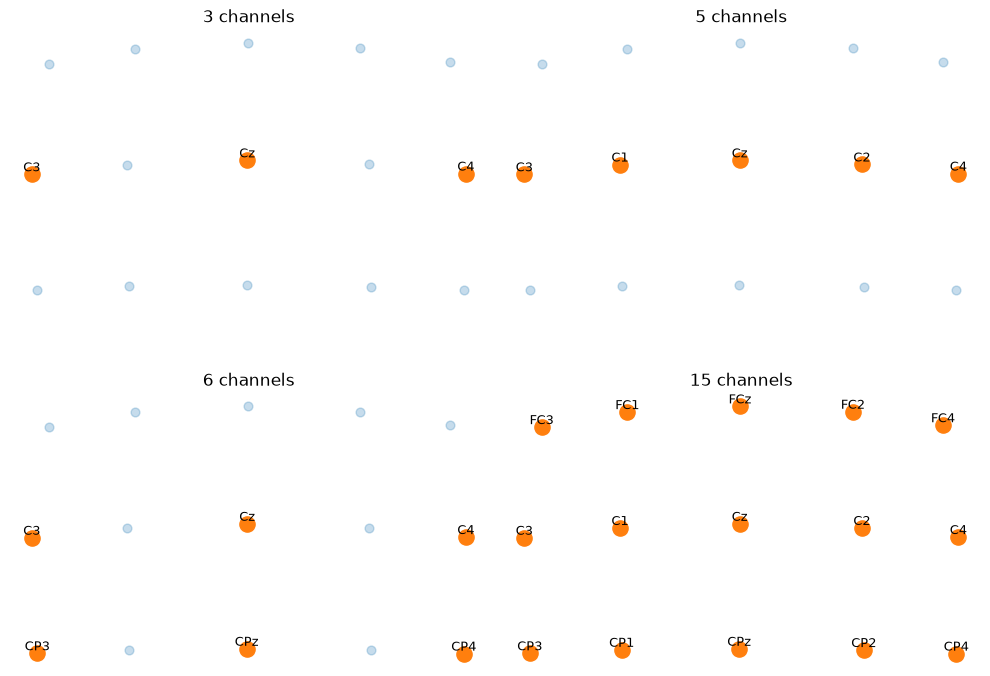

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import mne

raw_vis = mne.io.read_raw_edf(data_dir / "S001R04.edf", preload=False, verbose=False)

rename_map = {"Fc3.": "FC3", "Fc1.": "FC1", "Fcz.": "FCz", "Fc2.": "FC2", "Fc4.": "FC4", 
              "C3..": "C3", "C1..": "C1", "Cz..": "Cz", "C2..": "C2", "C4..": "C4",
              "Cp3.": "CP3", "Cp1.": "CP1", "Cpz.": "CPz", "Cp2.": "CP2", "Cp4.": "CP4"}

raw_vis.rename_channels(rename_map)
raw_vis.set_montage("standard_1005", match_case=False, on_missing="ignore")

positions = np.array([ch["loc"][:2] for ch in raw_vis.info["chs"]])
channel_names = np.array(raw_vis.ch_names)

channel_sets = {"3 channels": channels_3, "5 channels": channels_5, "6 channels": channels_6, "15 channels": channels_15}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, (title, selected_channels) in zip(axes.ravel(), channel_sets.items()):
    ax.scatter(positions[:, 0], positions[:, 1], s=40, alpha=0.25)
    
    mask = np.isin(channel_names, selected_channels)
    ax.scatter(positions[mask, 0], positions[mask, 1], s=120)
    
    for pos_x, pos_y, name in zip(positions[mask, 0], positions[mask, 1], channel_names[mask]):
        ax.text(pos_x, pos_y, name, fontsize=9, ha="center", va="bottom")
    
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.show()

### References

- Tuimebay, Y. et al. *Optimization of Low-Channel EEG Configurations and Temporal Segmentation for Motor Imagery Classification Using a Flexible EEGNet Framework*. Algorithms, 2026.

## 2. CSP Channel Selection Experiment

We compare CSP + LDA using 3, 5, 6, and 15 predefined sensorimotor channels.

All configurations use identical preprocessing, three CSP components, and Leave-One-Subject-Out cross-validation across 20 development subjects.

The goal is to determine whether additional motor-related channels improve cross-subject classification.

In [4]:
from mne.decoding import CSP
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import LeaveOneGroupOut, cross_validate
from sklearn.pipeline import make_pipeline
import pandas as pd

channel_datasets = {"3 channels": X_3, "5 channels": X_5, "6 channels": X_6, "15 channels": X_15}
logo = LeaveOneGroupOut()

scoring = {"accuracy": "accuracy",
           "balanced_accuracy": "balanced_accuracy",
           "f1_macro": "f1_macro"}

channel_results = []
channel_cv_results = {}

for name, X_data in channel_datasets.items():
    model = make_pipeline(CSP(n_components=3, reg=None, log=True, norm_trace=False, rank=None),
                          LinearDiscriminantAnalysis())

    cv_results = cross_validate(model, X_data, y, groups=groups, cv=logo, scoring=scoring)

    channel_cv_results[name] = cv_results

    channel_results.append({"Channels": name,
                            "Accuracy": cv_results["test_accuracy"].mean(),
                            "Balanced Accuracy": cv_results["test_balanced_accuracy"].mean(),
                            "Macro-F1": cv_results["test_f1_macro"].mean(),
                            "BA Std": cv_results["test_balanced_accuracy"].std()})

channel_results_df = pd.DataFrame(channel_results)

display(channel_results_df.round(3))

Computing rank from data with rank=None
    Using tolerance 5.7e-06 (2.2e-16 eps * 3 dim * 8.5e+09  max singular value)
    Estimated rank (data): 3
    data: rank 3 computed from 3 data channels with 0 projectors
Reducing data rank from 3 -> 3
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 5.7e-06 (2.2e-16 eps * 3 dim * 8.6e+09  max singular value)
    Estimated rank (data): 3
    data: rank 3 computed from 3 data channels with 0 projectors
Reducing data rank from 3 -> 3
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 5.6e-06 (2.2e-16 eps * 3 dim * 8.5e+09  max singular value)
    Estimated rank (data): 3
    data: rank 3 computed from 3 data channels with 0 projectors
Reducing data rank from 3 -> 3
Estimating class=0 covariance using EMPIRICAL
Done.
Estim

,Channels,Accuracy,Balanced Accuracy,Macro-F1,BA Std
0,3 channels,0.587,0.586,0.542,0.128
1,5 channels,0.556,0.557,0.484,0.075
2,6 channels,0.588,0.586,0.542,0.122
3,15 channels,0.586,0.581,0.525,0.123


### Channel Selection Results

The 3-channel and 6-channel CSP configurations achieved the highest balanced accuracy (0.586), while the 15-channel setup performed slightly lower (0.581) and the 5-channel setup showed the weakest performance (0.557).

These results suggest that, under the current CSP + LDA pipeline, increasing the number of motor-related channels does not necessarily improve cross-subject classification.

Because the 6-channel configuration matched the 3-channel baseline while using a literature-motivated sensorimotor extension, both configurations remain reasonable candidates for subsequent experiments.

### Subject-Level Channel Comparison

The 3- and 6-channel configurations achieved similar average performance.

We now compare balanced accuracy across individual subjects to examine whether additional channels provide consistent improvements or subject-specific effects.

In [5]:
subject_order = [groups[test_idx][0] for _, test_idx in logo.split(X_3, y, groups)]

subject_channel_df = pd.DataFrame({"Subject": subject_order,
                                   "3 channels": channel_cv_results["3 channels"]["test_balanced_accuracy"],
                                   "5 channels": channel_cv_results["5 channels"]["test_balanced_accuracy"],
                                   "6 channels": channel_cv_results["6 channels"]["test_balanced_accuracy"],
                                   "15 channels": channel_cv_results["15 channels"]["test_balanced_accuracy"]})

for name in ["5 channels", "6 channels", "15 channels"]:
    subject_channel_df[f"{name} - 3 channels"] = (subject_channel_df[name] - subject_channel_df["3 channels"])

display(subject_channel_df.round(3))

for name in ["5 channels", "6 channels", "15 channels"]:
    difference = subject_channel_df[f"{name} - 3 channels"]

    print(f"\n{name} vs 3 channels:")
    print("Subjects improved:", (difference > 0).sum(), "of 20")
    print("Mean BA difference:", round(difference.mean(), 3))

,Subject,3 channels,5 channels,6 channels,15 channels,5 channels - 3 channels,6 channels - 3 channels,15 channels - 3 channels
0,S001,0.616,0.673,0.688,0.688,0.057,0.072,0.072
1,S002,0.500,0.500,0.591,0.591,0.000,0.091,0.091
2,S003,0.577,0.535,0.481,0.401,-0.042,-0.096,-0.176
3,S004,0.609,0.609,0.543,0.522,0.000,-0.065,-0.087
4,S005,0.485,0.551,0.405,0.500,0.065,-0.080,0.015
5,S006,0.568,0.598,0.491,0.509,0.030,-0.077,-0.060
6,S007,0.978,0.609,0.912,0.957,-0.370,-0.066,-0.022
7,S008,0.628,0.648,0.629,0.618,0.020,0.001,-0.011
8,S009,0.426,0.390,0.470,0.574,-0.036,0.045,0.149
9,S010,0.690,0.619,0.548,0.586,-0.071,-0.143,-0.104



5 channels vs 3 channels:
Subjects improved: 9 of 20
Mean BA difference: -0.029

6 channels vs 3 channels:
Subjects improved: 10 of 20
Mean BA difference: 0.0

15 channels vs 3 channels:
Subjects improved: 11 of 20
Mean BA difference: -0.005


### Channel Selection Conclusion

The 3- and 6-channel CSP configurations achieved the highest mean balanced accuracy (**0.586**).

Subject-level analysis revealed substantial individual differences. The 6-channel configuration improved performance for 10 of 20 subjects but reduced performance for others, resulting in no overall improvement.

The 5- and 15-channel configurations also failed to outperform the 3-channel baseline.

**Conclusion:** Increasing the number of sensorimotor channels did not consistently improve cross-subject classification under the current CSP + LDA setup. The 3-channel configuration was retained for subsequent experiments due to its comparable performance and lower complexity.

## 3. Temporal Window Analysis

The previous experiment showed no clear improvement from increasing the number of motor channels.

We now investigate whether shorter EEG segments improve cross-subject classification.

Four temporal windows are compared: 0–4 s (baseline), 0–2 s, 1–3 s, and 2–4 s.

All experiments use the same three EEG channels (C3, Cz, C4) and identical preprocessing.

In [6]:
sfreq = 160
time_windows = {"0–4 s": (0, 4), "0–2 s": (0, 2), "1–3 s": (1, 3), "2–4 s": (2, 4)}
window_datasets = {}

for name, (start, end) in time_windows.items():
    start_sample = int(start * sfreq)
    end_sample = int(end * sfreq) + 1

    window_datasets[name] = X_3[:, :, start_sample:end_sample]

    print(f"{name}: {window_datasets[name].shape}")

print("\nSubjects:", len(np.unique(groups)))
print("Class distribution:", np.bincount(y))

0–4 s: (900, 3, 641)
0–2 s: (900, 3, 321)
1–3 s: (900, 3, 321)
2–4 s: (900, 3, 321)

Subjects: 20
Class distribution: [455 445]


### CSP Performance Across Temporal Windows

We evaluate CSP + LDA using four temporal windows (0–4 s, 0–2 s, 1–3 s, and 2–4 s).

All configurations use identical EEG channels and Leave-One-Subject-Out cross-validation.

Balanced accuracy and Macro-F1 are compared to determine whether shorter signal segments improve cross-subject classification.

In [7]:
window_results = []
window_cv_results = {}

for window_name, X_data in window_datasets.items():
    model = make_pipeline(CSP(n_components=3, reg=None, log=True, norm_trace=False, rank=None),
                          LinearDiscriminantAnalysis())

    cv_results = cross_validate(model, X_data, y, groups=groups, cv=logo, scoring=scoring)

    window_cv_results[window_name] = cv_results

    window_results.append({"Window": window_name,
                           "Accuracy": cv_results["test_accuracy"].mean(),
                           "Balanced Accuracy": cv_results["test_balanced_accuracy"].mean(),
                           "Macro-F1": cv_results["test_f1_macro"].mean(),
                           "BA Std": cv_results["test_balanced_accuracy"].std()})

window_results_df = pd.DataFrame(window_results)

display(window_results_df.round(3))

Computing rank from data with rank=None
    Using tolerance 5.7e-06 (2.2e-16 eps * 3 dim * 8.5e+09  max singular value)
    Estimated rank (data): 3
    data: rank 3 computed from 3 data channels with 0 projectors
Reducing data rank from 3 -> 3
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 5.7e-06 (2.2e-16 eps * 3 dim * 8.6e+09  max singular value)
    Estimated rank (data): 3
    data: rank 3 computed from 3 data channels with 0 projectors
Reducing data rank from 3 -> 3
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Computing rank from data with rank=None
    Using tolerance 5.6e-06 (2.2e-16 eps * 3 dim * 8.5e+09  max singular value)
    Estimated rank (data): 3
    data: rank 3 computed from 3 data channels with 0 projectors
Reducing data rank from 3 -> 3
Estimating class=0 covariance using EMPIRICAL
Done.
Estim

,Window,Accuracy,Balanced Accuracy,Macro-F1,BA Std
0,0–4 s,0.587,0.586,0.542,0.128
1,0–2 s,0.599,0.599,0.556,0.110
2,1–3 s,0.588,0.588,0.550,0.121
3,2–4 s,0.553,0.551,0.510,0.079


### Temporal Window Results

The 0–2 s window achieved the highest balanced accuracy (**0.599**) and Macro-F1 (**0.556**), slightly outperforming the 0–4 s baseline (0.586 and 0.542).

The 1–3 s window produced comparable results, whereas the 2–4 s window showed lower classification performance.

These findings suggest that earlier EEG segments may contain more useful information for the current CSP + LDA model. However, the improvement is small and requires subject-level evaluation.

### Subject-Level Temporal Window Comparison

We compare balanced accuracy across individual subjects for all four temporal windows.

The analysis focuses on whether the 0–2 s window consistently improves performance over the original 0–4 s baseline.

In [8]:
subject_order = np.unique(groups)

subject_window_df = pd.DataFrame({"Subject": subject_order,
                                  "0–4 s": window_cv_results["0–4 s"]["test_balanced_accuracy"],
                                  "0–2 s": window_cv_results["0–2 s"]["test_balanced_accuracy"],
                                  "1–3 s": window_cv_results["1–3 s"]["test_balanced_accuracy"],
                                  "2–4 s": window_cv_results["2–4 s"]["test_balanced_accuracy"]})

for name in ["0–2 s", "1–3 s", "2–4 s"]:
    subject_window_df[f"{name} - 0–4 s"] = (subject_window_df[name] - subject_window_df["0–4 s"])

display(subject_window_df.round(3))

for name in ["0–2 s", "1–3 s", "2–4 s"]:
    difference = subject_window_df[f"{name} - 0–4 s"]

    print(f"\n{name} vs 0–4 s:")
    print("Subjects improved:", (difference > 0).sum(), "of 20")
    print("Subjects worsened:", (difference < 0).sum(), "of 20")
    print("Mean BA difference:", round(difference.mean(), 3))

,Subject,0–4 s,0–2 s,1–3 s,2–4 s,0–2 s - 0–4 s,1–3 s - 0–4 s,2–4 s - 0–4 s
0,S001,0.616,0.686,0.665,0.570,0.070,0.049,-0.045
1,S002,0.500,0.523,0.524,0.523,0.023,0.024,0.023
2,S003,0.577,0.575,0.553,0.515,-0.002,-0.024,-0.062
3,S004,0.609,0.565,0.586,0.690,-0.043,-0.023,0.081
4,S005,0.485,0.551,0.482,0.449,0.065,-0.003,-0.036
5,S006,0.568,0.521,0.548,0.521,-0.048,-0.021,-0.048
6,S007,0.978,0.889,0.887,0.636,-0.089,-0.091,-0.342
7,S008,0.628,0.559,0.538,0.539,-0.069,-0.091,-0.090
8,S009,0.426,0.438,0.357,0.539,0.012,-0.068,0.113
9,S010,0.690,0.637,0.670,0.723,-0.054,-0.021,0.033



0–2 s vs 0–4 s:
Subjects improved: 12 of 20
Subjects worsened: 7 of 20
Mean BA difference: 0.013

1–3 s vs 0–4 s:
Subjects improved: 9 of 20
Subjects worsened: 10 of 20
Mean BA difference: 0.002

2–4 s vs 0–4 s:
Subjects improved: 7 of 20
Subjects worsened: 12 of 20
Mean BA difference: -0.035


### Temporal Window Conclusion

The 0–2 s window achieved the highest mean balanced accuracy (0.599), compared with 0.586 for the original 0–4 s baseline.

Subject-level analysis showed improvements for 12 of 20 subjects, decreases for seven, and no change for one subject.

Although shorter early EEG segments demonstrated a modest advantage, the improvement was not consistent across participants.

**Conclusion:** The 0–2 s window is a promising configuration for further experiments, but its superiority remains uncertain.

## 4. Baseline-Normalized Spectral Features (ERD/ERS)

We investigate whether changes in mu and beta power relative to pre-event EEG activity provide useful features for motor imagery classification.

First, we verify the availability of pre-event epochs. We then calculate percentage-based ERD/ERS and log-power-ratio features using baseline (−1–0 s) and task (0–2 s) intervals.

The analysis focuses on spectral power normalization; conventional amplitude baseline correction is not evaluated separately.

In [9]:
raw_check = mne.io.read_raw_edf(data_dir / "S001R04.edf", preload=True, verbose=False)

raw_check.set_eeg_reference(ref_channels="average", projection=False, verbose=False)
raw_check.filter(l_freq=8.0, h_freq=30.0, picks="eeg", verbose=False)

events_check, event_id_check = mne.events_from_annotations(raw_check, verbose=False)

epochs_check = mne.Epochs(raw_check, events_check, event_id={"T1": event_id_check["T1"], "T2": event_id_check["T2"]},
                          tmin=-0.5, tmax=4.0, picks="eeg", baseline=None, preload=True, reject_by_annotation=True, verbose=False)

print("Epochs:", len(epochs_check))
print("Shape:", epochs_check.get_data().shape)
print("Time range:", epochs_check.times[0], epochs_check.times[-1])

Epochs: 15
Shape: (15, 64, 721)
Time range: -0.5 4.0


### Epoch Rejection Check

The extended epoch extraction retained 15 motor imagery trials.

We inspect the MNE drop log to distinguish intentionally ignored rest events (T0) from rejected T1/T2 epochs.

In [10]:
from collections import Counter

drop_reasons = Counter(reason for entry in epochs_check.drop_log for reason in entry)


task_ids = {event_id_check["T1"], event_id_check["T2"]}

rejected_task_epochs = [(events_check[i, 2], reasons)
                        for i, reasons in enumerate(epochs_check.drop_log)
                        if events_check[i, 2] in task_ids and len(reasons) > 0]

print("Drop reasons:", drop_reasons)
print("Retained T1/T2 epochs:", len(epochs_check))
print("Rejected T1/T2 epochs:", len(rejected_task_epochs))
print("Rejected task details:", rejected_task_epochs)

Drop reasons: Counter({'IGNORED': 15})
Retained T1/T2 epochs: 15
Rejected T1/T2 epochs: 0
Rejected task details: []


### Baseline Duration Check

A 0.5 s baseline may be too short for stable mu-band power estimation.

We test a longer pre-event interval (−1.0 to 0 s) before calculating ERD/ERS features.

In [11]:
epochs_baseline = mne.Epochs(raw_check, events_check, event_id={"T1": event_id_check["T1"], "T2": event_id_check["T2"]},
                             tmin=-1.0, tmax=2.0, picks="eeg", baseline=None, preload=True, reject_by_annotation=True, verbose=False)

rejected_task = [reasons for i, reasons in enumerate(epochs_baseline.drop_log)
                 if events_check[i, 2] in {event_id_check["T1"], event_id_check["T2"]} and len(reasons) > 0]

print("Epochs:", len(epochs_baseline))
print("Shape:", epochs_baseline.get_data().shape)
print("Time range:", epochs_baseline.times[0], epochs_baseline.times[-1])
print("Rejected T1/T2 epochs:", len(rejected_task))

Epochs: 15
Shape: (15, 64, 481)
Time range: -1.0 2.0
Rejected T1/T2 epochs: 0


### ERD/ERS Feature Extraction

We calculate relative mu (8–13 Hz) and beta (13–30 Hz) power changes between the pre-event baseline (−1–0 s) and motor imagery period (0–2 s).

Welch's method is used to estimate band power. We first examine ERD/ERS features for S001R04 before extending the analysis to multiple subjects.

In [12]:
from scipy.signal import welch
import pandas as pd

sfreq = epochs_baseline.info["sfreq"]
times = epochs_baseline.times

baseline_mask = (times >= -1.0) & (times < 0.0)
task_mask = (times >= 0.0) & (times < 2.0)

channel_lookup = {ch.rstrip(".").upper(): ch for ch in epochs_baseline.ch_names}
motor_picks = [channel_lookup[ch.upper()] for ch in channels_3]

data_motor = epochs_baseline.get_data(picks=motor_picks)

baseline_data = data_motor[:, :, baseline_mask]
task_data = data_motor[:, :, task_mask]

bands = {"mu": (8, 13), "beta": (13, 30)}

def calculate_band_power(data, sfreq, fmin, fmax):
    freqs, psd = welch(data, fs=sfreq, nperseg=int(sfreq), axis=-1)
    band_mask = (freqs >= fmin) & (freqs < fmax)
    df = freqs[1] - freqs[0]
    return psd[..., band_mask].sum(axis=-1) * df

features = {}

for band_name, (fmin, fmax) in bands.items():
    baseline_power = calculate_band_power(baseline_data, sfreq, fmin, fmax)
    task_power = calculate_band_power(task_data, sfreq, fmin, fmax)

    erd_ers = ((task_power - baseline_power) / np.maximum(baseline_power, 1e-30) * 100)

    for channel_idx, channel_name in enumerate(channels_3):
        features[f"{channel_name}_{band_name}_erd_ers"] = (erd_ers[:, channel_idx])

erd_ers_df = pd.DataFrame(features)

erd_ers_df["Class"] = np.where(epochs_baseline.events[:, -1] == event_id_check["T1"], "T1", "T2")

print("ERD/ERS features:")
display(erd_ers_df.head().round(2))

print("\nMean ERD/ERS by class:")
display(erd_ers_df.groupby("Class").mean().round(2))

print("\nMissing values:", erd_ers_df.isna().sum().sum())

ERD/ERS features:


,C3_mu_erd_ers,Cz_mu_erd_ers,C4_mu_erd_ers,C3_beta_erd_ers,Cz_beta_erd_ers,C4_beta_erd_ers,Class
0,-44.27,-33.78,-17.79,-24.66,-41.85,-15.92,T2
1,-30.76,-66.91,106.86,-0.00,-4.60,103.36,T1
2,-82.72,286.68,-36.61,-50.88,45.30,-30.99,T1
3,-81.12,-74.50,-49.23,-75.27,-32.31,-52.40,T2
4,-52.20,-71.83,1.98,-41.84,80.96,60.68,T2



Mean ERD/ERS by class:


,C3_mu_erd_ers,Cz_mu_erd_ers,C4_mu_erd_ers,C3_beta_erd_ers,Cz_beta_erd_ers,C4_beta_erd_ers
Class,,,,,,
T1,7.68,101.40,-15.08,-10.33,9.67,2.47
T2,-43.08,25.05,3.12,-21.36,27.83,5.22



Missing values: 0


### Initial ERD/ERS Results

Mu-band power changes showed possible class-dependent patterns in C3 and C4, consistent with the expected contralateral motor imagery response.

However, several large positive ERS values were observed, particularly in Cz, suggesting that class means may be influenced by extreme observations.

**Next step:** Examine feature distributions and compare means with medians to assess the stability of ERD/ERS estimates.

### ERD/ERS Distribution Analysis

Initial results suggest possible contralateral mu desynchronization in C3 and C4, but several epochs show large positive ERS values.

We examine medians, variability, and extreme values to determine whether class-level differences are influenced by individual trials.

In [13]:
feature_columns = [col for col in erd_ers_df.columns if col != "Class"]

erd_summary = erd_ers_df.groupby("Class")[feature_columns].agg(["mean", "median", "std"])

print("ERD/ERS summary by class:")
display(erd_summary.round(2))

print("\nERD/ERS value ranges:")
display(erd_ers_df[feature_columns].agg(["min", "max"]).round(2))

print("\nClass distribution:")
display(erd_ers_df["Class"].value_counts())

ERD/ERS summary by class:


C3_mu_erd_ers                Cz_mu_erd_ers                C4_mu_erd_ers  \
               mean median     std          mean median     std          mean   
Class                                                                           
T1             7.68 -56.14  170.35        101.40  37.12  174.37        -15.08   
T2           -43.08 -52.20   39.95         25.05 -33.78  179.60          3.12   

                    C3_beta_erd_ers               Cz_beta_erd_ers         \
      median    std            mean median    std            mean median   
Class                                                                      
T1    -44.38  66.36          -10.33 -17.45  49.30            9.67   1.51   
T2    -17.79  53.67          -21.36 -24.66  39.84           27.83  44.37   

             C4_beta_erd_ers                
         std            mean median    std  
Class                                       
T1     70.98            2.47 -31.21  75.41  
T2     48.71            5.22   4.83  35.98


ERD/ERS value ranges:


,C3_mu_erd_ers,Cz_mu_erd_ers,C4_mu_erd_ers,C3_beta_erd_ers,Cz_beta_erd_ers,C4_beta_erd_ers
min,-83.65,-74.50,-70.92,-75.27,-74.28,-72.37
max,416.42,427.91,111.53,76.76,137.15,120.21



Class distribution:


Class
T1    8
T2    7
Name: count, dtype: int64

### ERD/ERS Distribution Results

Large differences between means and medians indicate that percentage-based ERD/ERS features are sensitive to extreme values.

For example, C3 mu ERD/ERS for T1 had a mean of +7.68% but a median of −56.14%. Maximum ERS values exceeded +400%.

These findings suggest that mean values alone may not reliably represent typical EEG power changes.

**Next step:** Inspect baseline and task power to identify the source of extreme ERS values.

### ERD/ERS Power Diagnostics

Large positive ERS values and differences between means and medians suggest that percentage-based features may be sensitive to individual trials.

We inspect baseline and task band power for extreme ERD/ERS observations before considering alternative feature transformations.

In [14]:
power_rows = []

for band_name, (fmin, fmax) in bands.items():
    baseline_power = calculate_band_power(baseline_data, sfreq, fmin, fmax)
    task_power = calculate_band_power(task_data, sfreq, fmin, fmax)

    for epoch_idx in range(len(epochs_baseline)):
        for channel_idx, channel_name in enumerate(channels_3):
            p_base = baseline_power[epoch_idx, channel_idx]
            p_task = task_power[epoch_idx, channel_idx]

            power_rows.append({"Epoch": epoch_idx,
                               "Class": erd_ers_df.loc[epoch_idx, "Class"],
                               "Channel": channel_name,
                               "Band": band_name,
                               "Baseline Power": p_base,
                               "Task Power": p_task,
                               "ERD/ERS (%)": (p_task - p_base) / max(p_base, 1e-30) * 100})

power_check_df = pd.DataFrame(power_rows)

extreme_power_df = power_check_df.loc[power_check_df["ERD/ERS (%)"].abs().nlargest(10).index].copy()

display(extreme_power_df.to_string(index=False, formatters={"Baseline Power": "{:.3e}".format,
                                                            "Task Power": "{:.3e}".format,
                                                            "ERD/ERS (%)": "{:.2f}".format}))

' Epoch Class Channel Band Baseline Power Task Power ERD/ERS (%)\n    11    T2      Cz   mu      7.440e-12  3.928e-11      427.91\n     7    T1      C3   mu      1.173e-11  6.057e-11      416.42\n     7    T1      Cz   mu      9.009e-12  4.651e-11      416.28\n     2    T1      Cz   mu      5.043e-12  1.950e-11      286.68\n    12    T1      Cz   mu      1.957e-11  5.137e-11      162.46\n     7    T1      Cz beta      2.254e-11  5.346e-11      137.15\n     7    T1      C4 beta      1.802e-11  3.968e-11      120.21\n    11    T2      C4   mu      1.996e-11  4.223e-11      111.53\n     1    T1      C4   mu      7.832e-12  1.620e-11      106.86\n     1    T1      C4 beta      1.923e-11  3.911e-11      103.36'

### Power Diagnostics Results

Extreme ERS values corresponded to substantial increases in task power relative to baseline power.

For example, some mu-band observations showed approximately fivefold power increases. Multiple extreme values occurred within the same trials.

These changes are mathematically consistent with the ERD/ERS formula, but their physiological origin remains uncertain.

**Next step:** Apply a log-power-ratio transformation to obtain a more symmetric representation of relative power changes.

### Log-Transformed ERD/ERS Features

Power diagnostics revealed several large positive ERS values, including trials with approximately fivefold increases in band power.

We calculate the log ratio between task and baseline power to obtain a more symmetric representation of relative spectral changes.

The transformed features will be examined before model evaluation.

In [15]:
power_check_df["Log Power Ratio"] = np.log(power_check_df["Task Power"].clip(lower=1e-30)
                                           / power_check_df["Baseline Power"].clip(lower=1e-30))

log_ratio_df = power_check_df.pivot(index=["Epoch", "Class"], columns=["Channel", "Band"],values="Log Power Ratio")

log_ratio_df.columns = [f"{channel}_{band}_log_ratio" for channel, band in log_ratio_df.columns]

log_ratio_df = log_ratio_df.reset_index()

print("Log Power Ratio features:")
display(log_ratio_df.head().round(3))

print("\nMedian Log Power Ratio by class:")
display(log_ratio_df.groupby("Class").median(numeric_only=True).round(3))

print("\nFeature ranges:")
display(log_ratio_df.drop(columns=["Epoch", "Class"]).agg(["min", "max"]).round(3))

Log Power Ratio features:


,Epoch,Class,C3_mu_log_ratio,Cz_mu_log_ratio,C4_mu_log_ratio,C3_beta_log_ratio,Cz_beta_log_ratio,C4_beta_log_ratio
0,0,T2,-0.585,-0.412,-0.196,-0.283,-0.542,-0.173
1,1,T1,-0.368,-1.106,0.727,-0.000,-0.047,0.710
2,2,T1,-1.756,1.352,-0.456,-0.711,0.374,-0.371
3,3,T2,-1.667,-1.366,-0.678,-1.397,-0.390,-0.742
4,4,T2,-0.738,-1.267,0.020,-0.542,0.593,0.474



Median Log Power Ratio by class:


,Epoch,C3_mu_log_ratio,Cz_mu_log_ratio,C4_mu_log_ratio,C3_beta_log_ratio,Cz_beta_log_ratio,C4_beta_log_ratio
Class,,,,,,,
T1,8.0,-1.016,0.258,-0.590,-0.194,0.013,-0.374
T2,6.0,-0.738,-0.412,-0.196,-0.283,0.367,0.047



Feature ranges:


,C3_mu_log_ratio,Cz_mu_log_ratio,C4_mu_log_ratio,C3_beta_log_ratio,Cz_beta_log_ratio,C4_beta_log_ratio
min,-1.811,-1.366,-1.235,-1.397,-1.358,-1.286
max,1.642,1.664,0.749,0.570,0.864,0.789


### Log Power Ratio Results

Log transformation provided a more symmetric representation of relative mu and beta power changes.

Median mu-band log ratios showed class differences, particularly in C4 and Cz. However, the expected contralateral pattern was not consistently observed across C3 and C4.

These preliminary results are based on only 15 trials from one recording. Cross-subject evaluation is required to determine whether log-power-ratio features improve classification.

## 5. Cross-Subject Log Power Ratio Features

The single-recording analysis revealed possible class-dependent differences in relative mu and beta power.

We now extract six log-power-ratio features from all 20 subjects using a 1 s pre-event baseline and a 2 s motor imagery window.

The resulting feature dataset will be evaluated using subject-independent cross-validation.

In [16]:
log_ratio_rows = []
log_ratio_labels = []
log_ratio_groups = []

for subject in subjects:
    for run in runs:
        recording_id = f"{subject}R{run}"

        raw = mne.io.read_raw_edf(data_dir / f"{recording_id}.edf", preload=True, verbose=False)
        raw.set_eeg_reference(ref_channels="average", projection=False, verbose=False)
        raw.filter(l_freq=8.0, h_freq=30.0, picks="eeg", verbose=False)

        events, event_id = mne.events_from_annotations(raw, verbose=False)

        epochs = mne.Epochs(raw, events, event_id={"T1": event_id["T1"], "T2": event_id["T2"]},
                            tmin=-1.0, tmax=2.0, picks="eeg", baseline=None, preload=True, reject_by_annotation=True, verbose=False)

        channel_lookup = {ch.rstrip(".").upper(): ch for ch in epochs.ch_names}
        selected = [channel_lookup[ch.upper()] for ch in channels_3]

        data = epochs.get_data(picks=selected)
        baseline_mask = (epochs.times >= -1.0) & (epochs.times < 0.0)
        task_mask = (epochs.times >= 0.0) & (epochs.times < 2.0)

        baseline_data = data[:, :, baseline_mask]
        task_data = data[:, :, task_mask]

        band_features = {}

        for band_name, (fmin, fmax) in bands.items():
            p_base = calculate_band_power(baseline_data, epochs.info["sfreq"], fmin, fmax)
            p_task = calculate_band_power(task_data, epochs.info["sfreq"], fmin, fmax)

            log_ratio = np.log(p_task.clip(min=1e-30) / p_base.clip(min=1e-30))

            for channel_idx, channel_name in enumerate(channels_3):
                band_features[f"{channel_name}_{band_name}_log_ratio"] = (log_ratio[:, channel_idx])

        log_ratio_rows.extend({name: values[i] for name, values in band_features.items()}
                              for i in range(len(epochs)))

        log_ratio_labels.extend(np.where(epochs.events[:, -1] == event_id["T1"], 0, 1))
        log_ratio_groups.extend([subject] * len(epochs))

X_log_ratio = pd.DataFrame(log_ratio_rows)
y_log_ratio = np.array(log_ratio_labels)
groups_log_ratio = np.array(log_ratio_groups)

print("Feature shape:", X_log_ratio.shape)
print("Class distribution:", np.bincount(y_log_ratio))
print("Subjects:", len(np.unique(groups_log_ratio)))
print("Missing values:", X_log_ratio.isna().sum().sum())
print("All finite:", np.isfinite(X_log_ratio.to_numpy()).all())

print("Labels match existing dataset:", np.array_equal(y_log_ratio, y))
print("Subjects match existing dataset:", np.array_equal(groups_log_ratio, groups))

Feature shape: (900, 6)
Class distribution: [455 445]
Subjects: 20
Missing values: 0
All finite: True
Labels match existing dataset: True
Subjects match existing dataset: True


### Cross-Subject Feature Validation

Six log-power-ratio features were successfully extracted from 900 motor imagery epochs across 20 subjects.

All values are finite, with no missing observations. Class labels and subject assignments match the original dataset.

The features are ready for subject-independent model evaluation.

## 6. Log Power Ratio Model Evaluation

We evaluate whether baseline-normalized mu and beta power features can distinguish left- and right-hand motor imagery across unseen subjects.

A StandardScaler + LDA pipeline is evaluated using Leave-One-Subject-Out cross-validation.

Results will be compared with the previous CSP + LDA baselines on the same 20 subjects.

In [17]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

log_ratio_model = make_pipeline(StandardScaler(),
                                LinearDiscriminantAnalysis())

log_ratio_cv = cross_validate(log_ratio_model, X_log_ratio, y_log_ratio, groups=groups_log_ratio, cv=logo, scoring=scoring)

log_ratio_results = pd.DataFrame([{"Model": "Log Power Ratio + LDA",
                                   "Accuracy": log_ratio_cv["test_accuracy"].mean(),
                                   "Balanced Accuracy": log_ratio_cv["test_balanced_accuracy"].mean(),
                                   "Macro-F1": log_ratio_cv["test_f1_macro"].mean(),
                                   "BA Std": log_ratio_cv["test_balanced_accuracy"].std()}])

comparison_results = pd.DataFrame([
    {
        "Model": "CSP + LDA (0–4 s)",
        "Balanced Accuracy": window_cv_results["0–4 s"]["test_balanced_accuracy"].mean(),
        "Macro-F1": window_cv_results["0–4 s"]["test_f1_macro"].mean()
    },
    {
        "Model": "CSP + LDA (0–2 s)",
        "Balanced Accuracy": window_cv_results["0–2 s"]["test_balanced_accuracy"].mean(),
        "Macro-F1": window_cv_results["0–2 s"]["test_f1_macro"].mean()
    },
    {
        "Model": "Log Power Ratio + LDA",
        "Balanced Accuracy": log_ratio_results["Balanced Accuracy"].iloc[0],
        "Macro-F1": log_ratio_results["Macro-F1"].iloc[0]
    }])

print("Log Power Ratio model:")
display(log_ratio_results.round(3))

print("\nModel comparison:")
display(comparison_results.round(3))

Log Power Ratio model:


,Model,Accuracy,Balanced Accuracy,Macro-F1,BA Std
0,Log Power Ratio + LDA,0.553,0.555,0.548,0.075



Model comparison:


,Model,Balanced Accuracy,Macro-F1
0,CSP + LDA (0–4 s),0.586,0.542
1,CSP + LDA (0–2 s),0.599,0.556
2,Log Power Ratio + LDA,0.555,0.548


### Log Power Ratio Model Results

Log Power Ratio + LDA achieved a mean balanced accuracy of **0.555** and Macro-F1 of **0.548** across 20 subjects.

The model did not outperform CSP + LDA (0–2 s), which achieved a balanced accuracy of 0.599 and Macro-F1 of 0.556.

Log-power-ratio features showed lower between-subject variability, but this did not translate into higher average balanced accuracy.

**Conclusion:** Baseline-normalized spectral features did not improve classification as a standalone representation. Their potential complementary value to CSP remains unexplored.

### Subject-Level Model Comparison

We compare Log Power Ratio + LDA against the best CSP + LDA configuration (0–2 s) for each subject.

This analysis examines whether baseline-normalized spectral features provide advantages for subjects where CSP performs poorly.

In [18]:
subject_model_df = pd.DataFrame({"Subject": np.unique(groups),
                                 "CSP BA": window_cv_results["0–2 s"]["test_balanced_accuracy"],
                                 "Log Ratio BA": log_ratio_cv["test_balanced_accuracy"],
                                 "CSP Macro-F1": window_cv_results["0–2 s"]["test_f1_macro"],
                                 "Log Ratio Macro-F1": log_ratio_cv["test_f1_macro"]})

subject_model_df["BA Difference"] = (subject_model_df["Log Ratio BA"] - subject_model_df["CSP BA"])

display(subject_model_df.round(3))

difference = subject_model_df["BA Difference"]

print("Log Ratio better:", (difference > 0).sum(), "of 20")
print("CSP better:", (difference < 0).sum(), "of 20")
print("Equal performance:", (difference == 0).sum(), "of 20")
print("Mean BA difference:", round(difference.mean(), 3))

,Subject,CSP BA,Log Ratio BA,CSP Macro-F1,Log Ratio Macro-F1,BA Difference
0,S001,0.686,0.602,0.681,0.598,-0.084
1,S002,0.523,0.603,0.387,0.595,0.080
2,S003,0.575,0.464,0.570,0.460,-0.111
3,S004,0.565,0.671,0.459,0.656,0.106
4,S005,0.551,0.542,0.474,0.530,-0.009
5,S006,0.521,0.533,0.509,0.532,0.012
6,S007,0.889,0.623,0.889,0.622,-0.267
7,S008,0.559,0.444,0.545,0.443,-0.116
8,S009,0.438,0.551,0.398,0.550,0.113
9,S010,0.637,0.512,0.610,0.511,-0.125


Log Ratio better: 6 of 20
CSP better: 14 of 20
Equal performance: 0 of 20
Mean BA difference: -0.045


### ERD/ERS Experiment Conclusion

Log Power Ratio + LDA achieved a mean balanced accuracy of **0.555**, compared with **0.599** for CSP + LDA (0–2 s).

Subject-level analysis showed that Log Power Ratio performed better for 6 of 20 subjects, while CSP performed better for 14.

Although baseline-normalized spectral features benefited some participants, they did not consistently improve cross-subject classification.

**Conclusion:** CSP remains the stronger standalone approach. Log-power-ratio features may contain complementary information, but their potential benefit requires further evaluation.

## 7. Filter Bank CSP (FBCSP)
### Research Motivation: Filter Bank CSP

Chang et al. (2026) compared classical and deep learning approaches for motor imagery classification on the PhysioNet EEG dataset.

In their 30-subject nested LOSO experiment, FBCSP + SVM achieved **57.73% accuracy**, compared with **53.06%** for standard CSP + SVM.

These results motivate investigating whether frequency-specific spatial filtering improves cross-subject classification.

**Our approach:** We evaluate FBCSP using four predefined frequency bands (8–12, 12–16, 16–22, and 22–30 Hz), initially retaining three EEG channels and a 0–2 s task window.

The frequency boundaries and classifier configuration are our experimental choices, not an exact reproduction of the published method.

**Reference:** [Chang et al. (2026), *Evaluating Validation Strategies in Motor Imagery EEG*](https://doi.org/10.3390/brainsci16080873).


The previous experiments showed that standard CSP outperformed standalone baseline-normalized spectral features.

We now investigate whether extracting spatial patterns separately from multiple frequency bands improves classification.

Four frequency bands spanning 8–30 Hz are defined for the initial FBCSP experiment. The three-channel configuration and 0–2 s task window are retained.

In [19]:
filter_bands = {"8–12 Hz": (8, 12), "12–16 Hz": (12, 16), "16–22 Hz": (16, 22), "22–30 Hz": (22, 30)}

for band_name, (fmin, fmax) in filter_bands.items():
    print(f"{band_name}: {fmin}–{fmax} Hz")

print("\nNumber of frequency bands:", len(filter_bands))

8–12 Hz: 8–12 Hz
12–16 Hz: 12–16 Hz
16–22 Hz: 16–22 Hz
22–30 Hz: 22–30 Hz

Number of frequency bands: 4


### Filter Bank EEG Preparation

Following the FBCSP motivation from Chang et al. (2026), we prepare separate EEG signals for four predefined frequency bands.

Each band is filtered from continuous EEG before epoch extraction to minimize edge artifacts.

We retain C3, Cz, C4 and the 0–2 s task window, ensuring identical epochs and class labels across all frequency bands.

In [20]:
X_fb_list = []
y_fb_list = []
groups_fb_list = []

band_names = list(filter_bands)

for subject in subjects:
    for run in runs:
        recording_id = f"{subject}R{run}"

        raw = mne.io.read_raw_edf( data_dir / f"{recording_id}.edf", preload=True, verbose=False)

        raw.set_eeg_reference(ref_channels="average", projection=False, verbose=False)

        events, event_id = mne.events_from_annotations(raw, verbose=False)

        channel_lookup = {ch.rstrip(".").upper(): ch for ch in raw.ch_names}
        selected_channels = [channel_lookup[ch.upper()] for ch in channels_3]

        recording_bands = []
        reference_events = None

        for band_name, (fmin, fmax) in filter_bands.items():
            raw_band = raw.copy().pick(selected_channels)
            raw_band.filter(l_freq=fmin, h_freq=fmax, verbose=False)

            epochs = mne.Epochs(raw_band, events, event_id={"T1": event_id["T1"], "T2": event_id["T2"]},
                                tmin=0.0, tmax=2.0, baseline=None, preload=True, reject_by_annotation=True, verbose=False)

            epochs.reorder_channels(selected_channels)

            if reference_events is None:
                reference_events = epochs.events.copy()
            else:
                assert np.array_equal(epochs.events, reference_events)

            recording_bands.append(epochs.get_data())

        X_fb_list.append(np.stack(recording_bands, axis=1))

        y_fb_list.append(np.where(reference_events[:, -1] == event_id["T1"], 0, 1))
        groups_fb_list.extend([subject] * len(reference_events))

X_fb = np.concatenate(X_fb_list, axis=0)
y_fb = np.concatenate(y_fb_list)
groups_fb = np.array(groups_fb_list)

print("FBCSP data shape:", X_fb.shape)
print("Frequency bands:", band_names)
print("Class distribution:", np.bincount(y_fb))
print("Subjects:", len(np.unique(groups_fb)))
print("All finite:", np.isfinite(X_fb).all())

print("Labels match:", np.array_equal(y_fb, y))
print("Subjects match:", np.array_equal(groups_fb, groups))

FBCSP data shape: (900, 4, 3, 321)
Frequency bands: ['8–12 Hz', '12–16 Hz', '16–22 Hz', '22–30 Hz']
Class distribution: [455 445]
Subjects: 20
All finite: True
Labels match: True
Subjects match: True


### Filter Bank Data Validation

Four frequency-specific EEG representations were successfully prepared for 900 motor imagery epochs across 20 subjects.

All data are finite, and class labels and subject assignments match the original dataset.

The filter bank is ready for CSP feature extraction and subject-independent evaluation.

### FBCSP + LDA Evaluation

Motivated by the FBCSP results reported by Chang et al. (2026), we fit a separate CSP transformer for each frequency band and concatenate the extracted features.

Three CSP components per band produce 12 features per epoch. LDA is used for classification.

All CSP transformations are fitted within the training folds of Leave-One-Subject-Out cross-validation to prevent data leakage.

The model is compared with the standard CSP + LDA baseline using the same 20 subjects and 0–2 s task window.

In [21]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import make_pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import cross_validate
from mne.decoding import CSP

class FilterBankCSP(BaseEstimator, TransformerMixin):
    def __init__(self, n_components=3):
        self.n_components = n_components

    def fit(self, X, y):
        self.csps_ = []

        for band_idx in range(X.shape[1]):
            csp = CSP(n_components=self.n_components, reg=None, log=True, norm_trace=False, rank=None)

            with mne.use_log_level("WARNING"):
                csp.fit(X[:, band_idx, :, :], y)

            self.csps_.append(csp)

        return self

    def transform(self, X):
        features = [csp.transform(X[:, band_idx, :, :])
                    for band_idx, csp in enumerate(self.csps_)]

        return np.concatenate(features, axis=1)

fbcsp_model = make_pipeline(FilterBankCSP(n_components=3),
                            LinearDiscriminantAnalysis())

fbcsp_cv = cross_validate(fbcsp_model, X_fb, y_fb, groups=groups_fb, cv=logo, scoring=scoring)

fbcsp_results = pd.DataFrame([{"Model": "FBCSP + LDA",
                               "Accuracy": fbcsp_cv["test_accuracy"].mean(),
                               "Balanced Accuracy": fbcsp_cv["test_balanced_accuracy"].mean(),
                               "Macro-F1": fbcsp_cv["test_f1_macro"].mean(),
                               "BA Std": fbcsp_cv["test_balanced_accuracy"].std()}])

display(fbcsp_results.round(3))

,Model,Accuracy,Balanced Accuracy,Macro-F1,BA Std
0,FBCSP + LDA,0.597,0.597,0.562,0.109


### FBCSP Evaluation Results

FBCSP + LDA achieved a mean balanced accuracy of **0.597** and Macro-F1 of **0.562** across 20 subjects.

Compared with standard CSP + LDA (0–2 s), FBCSP produced nearly identical balanced accuracy (0.597 vs. 0.599) and slightly higher Macro-F1 (0.562 vs. 0.556).

**Conclusion:** Frequency-specific CSP features did not provide a clear improvement under the current configuration. Further subject-level analysis is needed to assess individual differences.

### Subject-Level FBCSP Comparison

We compare standard CSP and FBCSP performance across individual subjects using the same LOSO folds.

The analysis examines whether frequency-specific CSP features provide consistent improvements or subject-dependent effects.

In [22]:
subject_fbcsp_df = pd.DataFrame({"Subject": np.unique(groups),
                                 "CSP BA": window_cv_results["0–2 s"]["test_balanced_accuracy"],
                                 "FBCSP BA": fbcsp_cv["test_balanced_accuracy"],
                                 "CSP Macro-F1": window_cv_results["0–2 s"]["test_f1_macro"],
                                 "FBCSP Macro-F1": fbcsp_cv["test_f1_macro"]})

subject_fbcsp_df["BA Difference"] = (subject_fbcsp_df["FBCSP BA"] - subject_fbcsp_df["CSP BA"])

display(subject_fbcsp_df.round(3))

difference = subject_fbcsp_df["BA Difference"]

print("FBCSP better:", (difference > 0).sum(), "of 20")
print("CSP better:", (difference < 0).sum(), "of 20")
print("Equal performance:", (difference == 0).sum(), "of 20")
print("Mean BA difference:", round(difference.mean(), 3))

,Subject,CSP BA,FBCSP BA,CSP Macro-F1,FBCSP Macro-F1,BA Difference
0,S001,0.686,0.640,0.681,0.630,-0.045
1,S002,0.523,0.617,0.387,0.593,0.094
2,S003,0.575,0.598,0.570,0.595,0.023
3,S004,0.565,0.543,0.459,0.418,-0.022
4,S005,0.551,0.571,0.474,0.489,0.021
5,S006,0.521,0.533,0.509,0.532,0.012
6,S007,0.889,0.909,0.889,0.910,0.020
7,S008,0.559,0.689,0.545,0.689,0.129
8,S009,0.438,0.446,0.398,0.350,0.009
9,S010,0.637,0.693,0.610,0.689,0.057


FBCSP better: 11 of 20
CSP better: 7 of 20
Equal performance: 2 of 20
Mean BA difference: -0.002


### FBCSP Experiment Conclusion

FBCSP + LDA achieved a balanced accuracy of **0.597**, compared with **0.599** for standard CSP + LDA.

Subject-level analysis showed improvements for 11 subjects, decreases for seven, and unchanged performance for two.

Chang et al. (2026) reported an improvement from 53.06% accuracy (CSP + SVM) to 57.73% (FBCSP + SVM) under nested LOSO on 30 subjects.

Our experiment did not reproduce a comparable improvement. However, the evaluation protocols, classifiers, input durations, and subject cohorts differed.

**Conclusion:** Frequency-specific spatial filtering remains a promising direction, but the current three-channel FBCSP + LDA configuration does not consistently outperform standard CSP.

**Next step:** Evaluate whether classifier choice and additional sensorimotor channels affect FBCSP performance.

**Reference:** [Chang et al. (2026), Brain Sciences](https://doi.org/10.3390/brainsci16080873).

## 8. Overall Conclusion and Future Work

This notebook investigated several strategies for improving cross-subject motor imagery classification, motivated by recent EEG research.

### Key Findings

- **Channel selection:** Three- and six-channel CSP + LDA configurations achieved similar balanced accuracy (0.586). Increasing the number of channels did not consistently improve performance under the tested settings.
- **Temporal windows:** The 0–2 s window achieved the highest CSP + LDA balanced accuracy (0.599), compared with 0.586 for the original 0–4 s window.
- **Baseline-normalized features:** Log Power Ratio + LDA achieved 0.555 balanced accuracy, below the CSP baseline.
- **Filter Bank CSP:** FBCSP + LDA achieved 0.597 balanced accuracy and 0.562 Macro-F1. Frequency-specific features improved performance for some subjects but did not provide a consistent overall advantage.

### Methodological Limitations

The experiments used predefined model configurations and sequential optimization. Channel selection, temporal windows, feature extraction, and classifier choices were not jointly optimized.

All reported results are exploratory LOSO estimates on 20 development subjects. They should not be interpreted as independent performance estimates for the final selected pipeline.

### Next Research Direction

The next stage will investigate joint model selection across EEG channel configurations, CSP/FBCSP feature extraction, and LDA/SVM classifiers.

Subject-aware nested cross-validation will be used to evaluate model selection while avoiding information leakage.

Feature fusion and ensemble methods may be considered after evaluating the individual models and their prediction errors.

**Final takeaway:** The experiments identified promising configurations and substantial subject-level variability, but no method produced a clear, consistent improvement. Further evaluation is required before selecting the final model.